# RBM for Potts Model

### Dataset

[WW Domain protein sequences (PF00397), used by Tubiana, Cocco, and Monasson (2019)](https://elifesciences.org/articles/39397). See [github page of authors](https://github.com/jertubiana/PGM) for orignal dataset.

Shape: (17233, 31)
First sequence: LPGEWKPCQDIT-GDIYYFNFANGQSMWDHP


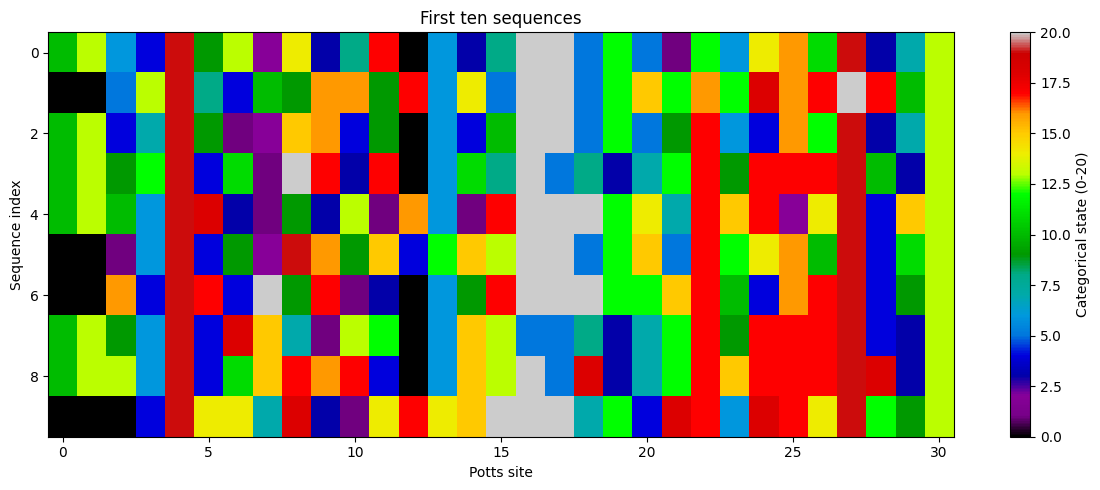

In [1]:

import numpy as np
import matplotlib.pyplot as plt

X = np.load("data/WW_potts_raw.npy")
alphabet = "-ACDEFGHIKLMNPQRSTVWY"

print("Shape:", X.shape)
print("First sequence:", "".join(alphabet[i] for i in X[0]))

plt.figure(figsize=(12, 5))
plt.imshow(X[:10], aspect="auto", interpolation="nearest",
           cmap="nipy_spectral", vmin=0, vmax=20)
plt.xlabel("Potts site")
plt.ylabel("Sequence index")
plt.title("First ten sequences")
plt.colorbar(label="Categorical state (0-20)")
plt.tight_layout()
plt.show()


### From Ising RBM to Categorical (Potts) RBM

Recall the energy of our binary-visible, binary-hidden RBM:

$$
E(\mathbf v,\mathbf h)
=-\sum_i a_i v_i
-\sum_\mu b_\mu h_\mu
-\sum_{i,\mu}W_{i\mu}v_i h_\mu.
$$

#### 1. Categorical representation

For amino-acid sequences, each visible site can take one of $q=21$ states: 20 amino acids and one gap.

Let $v_i\in\mathcal A$, where

$$
\mathcal A=\{-,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y\}.
$$

Instead of assigning a single numerical value to each state, we introduce state-dependent visible biases and weights:

$$
\boxed{
E(\mathbf v,\mathbf h)
=-\sum_i a_i(v_i)
-\sum_\mu b_\mu h_\mu
-\sum_{i,\mu}W_{i\mu}(v_i)h_\mu.
}
$$

Here:

- $a_i(a)$: bias associated with amino acid $a$ at site $i$.
- $W_{i\mu}(a)$: coupling between hidden mode $\mu$ and amino acid $a$ at site $i$.
- $b_\mu$: hidden bias, unchanged from the binary RBM.

For $N$ sites and $M$ hidden units, the parameter dimensions are

$$
a:(N,q),\qquad W:(N,q,M),\qquad b:(M).
$$

Thus, every hidden mode learns a pattern of preferences across all amino-acid positions.

#### 2. Equivalent one-hot representation

Alternatively, represent each categorical variable using a one-hot vector:

$$
x_{ia}=\mathbf 1[v_i=a],\qquad
\sum_{a=1}^{q}x_{ia}=1.
$$

We can flatten the one-hot vectors into $\mathbf x\in\{0,1\}^{Nq}$, obtaining the familiar RBM energy:

$$
E(\mathbf x,\mathbf h)
=-\mathbf a^T\mathbf x
-\mathbf b^T\mathbf h
-\mathbf x^TW\mathbf h,
$$

where $\mathbf a\in\mathbb R^{Nq}$ and $W\in\mathbb R^{Nq\times M}$.

Separating the categorical index $a$ again gives

$$
\boxed{
E(\mathbf x,\mathbf h)
=-\sum_{i,a}a_{ia}x_{ia}
-\sum_\mu b_\mu h_\mu
-\sum_{i,a,\mu}W_{ia\mu}x_{ia}h_\mu.
}
$$

Both representations describe exactly the same categorical RBM.

**Connection to the Potts Hopfield model:** We can similarly express its pairwise coupling tensor $J_{iajb}$ as an $Nq\times Nq$ matrix. A suitable factorization $J=WW^T$ then yields weights $W_{ia\mu}$. This provides an exact Gaussian-hidden RBM representation when the factorization is valid (possibly after a diagonal shift). Our **binary-hidden Potts-RBM**, however, is trained directly and generally generates higher-order effective interactions rather than merely reproducing pairwise Potts couplings.

#### 3. Hidden-layer sampling: sigmoid

The hidden variables remain binary, so their conditional distributions still factorize:

$$
\boxed{
P(\mathbf h\mid\mathbf v)
=\prod_\mu P(h_\mu\mid\mathbf v)
}
$$

with

$$
\boxed{
P(h_\mu=1\mid\mathbf v)
=\sigma\left(
b_\mu+\sum_i W_{i\mu}(v_i)
\right).
}
$$

In one-hot notation, the sum becomes $\sum_{i,a}W_{ia\mu}x_{ia}$.

Each hidden mode therefore responds to the combined contributions of the amino acids present throughout the sequence.

#### 4. Visible-layer sampling: softmax

The important change occurs when reconstructing visible variables from the hidden configuration.

Define the effective field for amino acid $a$ at site $i$:

$$
\boxed{
z_{ia}=a_{ia}+\sum_\mu W_{ia\mu}h_\mu.
}
$$

Because visible sites have no direct interactions, their conditional distribution factorizes:

$$
P(\mathbf v\mid\mathbf h)
=\prod_i P(v_i\mid\mathbf h).
$$

However, each site must occupy **exactly one categorical state**, rather than independently activating multiple binary units.

The normalization therefore becomes

$$
\begin{aligned}
P(\mathbf v\mid\mathbf h)
&=\frac{\exp\left(\sum_i z_{i,v_i}\right)}
{\sum_{\mathbf v'}\exp\left(\sum_i z_{i,v_i'}\right)}\\
&=\prod_i\frac{e^{z_{i,v_i}}}{\sum_{a=1}^{q}e^{z_{ia}}}.
\end{aligned}
$$

Hence,

$$
\boxed{
P(v_i=a\mid\mathbf h)
=\frac{
\exp\left(a_{ia}+\sum_\mu W_{ia\mu}h_\mu\right)
}{
\sum_{c=1}^{q}\exp\left(a_{ic}+\sum_\mu W_{ic\mu}h_\mu\right)
}.
}
$$

This is the **softmax distribution** over the \(q=21\) possible states.

Every hidden mode contributes to the effective field of each amino acid, but the categorical softmax ensures that only one state is sampled at each position.

#### 5. Training

The training procedure remains essentially identical to our original RBM:

1. **Positive phase:** Sample hidden units from the observed amino-acid sequences using sigmoid.
2. **Negative phase:** Run block Gibbs sampling, alternating between categorical softmax sampling for visible sites and Bernoulli sampling for hidden units.
3. **Parameter updates:** Match the data and model expectations, now using categorical indicator variables.

For example, the weight gradient becomes

$$
\boxed{
\frac{\partial\log\mathcal L}{\partial W_{ia\mu}}
=
\langle x_{ia}h_\mu\rangle_{\mathrm{data}}
-
\langle x_{ia}h_\mu\rangle_{\mathrm{model}}.
}
$$

The visible-bias gradients similarly involve the difference between observed and generated amino-acid frequencies.

**In summary:** The Potts-RBM preserves the architecture and learning principles of the binary RBM. The differences are the additional categorical dimension in its parameters and the replacement of Bernoulli visible sampling with categorical softmax sampling. Shared hidden modes allow the model to learn statistical dependencies between amino acids at different sequence positions.


In [2]:
import torch
from torch.utils.data import DataLoader

torch.manual_seed(42)
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")

In [3]:
def sigmoid(x):
    return torch.sigmoid(x)


def softmax(x, dim):
    return torch.softmax(x, dim)


def hidden_probabilities(v, W, b_h):
    """v: [N, q] or [batch, N, q]; W: [N, q, M]; b_h: [M],
    returns [M] or [batch, M]"""
    return sigmoid(
        v.flatten(start_dim=-2) @ W.flatten(start_dim=0, end_dim=1) + b_h
    )


def visible_probabilities(h, W, b_v):
    """h: [M] or [batch, M]; W: [N, q, M]; b_v: [N, q],
    returns [N, q] or [batch, N, q]"""
    logits = h @ W.flatten(start_dim=0, end_dim=1).T
    # h.shape[:-1] supplies batch dim, b_v.shape supplies [N, q] dim
    logits = logits.reshape(*h.shape[:-1], *b_v.shape) + b_v
    return softmax(logits, -1)   # softmax in q dim


def sample_visible(probs):
    """Samples from visible probs of shape [N, q] or [batch, N, q],
    returns one-hot encoded samples of shape [N, q] or [batch, N, q]"""
    # treats the last dimension as categories, independent samples per row
    indices = torch.distributions.Categorical(probs=probs).sample()
    one_hot = torch.nn.functional.one_hot(
        indices, num_classes=probs.shape[-1]
    ).to(dtype=probs.dtype)
    return one_hot

In [4]:
@torch.no_grad()
def Block_Gibbs_sampling(v, W, b_v, b_h, n):
    """Perform n Gibbs steps for one visible state or a batch of states."""
    for _ in range(n):
        # Sample hidden states conditioned on visible states
        h = torch.bernoulli(hidden_probabilities(v, W, b_h))
        # Sample visible states conditioned on hidden states
        v = sample_visible(visible_probabilities(h, W, b_v))
    return v


@torch.no_grad()
def persistent_gibbs_sampling(v_set, W, b_v, b_h, n=20):
    """Advance persistent visible chains of shape [num_chains, N]."""
    samples = Block_Gibbs_sampling(v_set, W, b_v, b_h, n)
    # Draw hidden states conditioned on the final visible states.
    samples_h = torch.bernoulli(hidden_probabilities(samples, W, b_h))
    return samples, samples_h

In [5]:
def vh_data(v_set, W, b_h):
    """v_set: [batch, N, q] -> expectation: [N, q, M]."""
    probs_h = hidden_probabilities(v_set, W, b_h)   # [batch, M]
    return torch.einsum("biq,bm->iqm", v_set, probs_h) / len(v_set)


def v_data(v_set, W, b_h):
    """v_set: [batch, N, q] -> expectation: [N, q]."""
    return v_set.mean(dim=0)


def h_data(v_set, W, b_h):
    """v_set: [batch, N, q] -> expectation: [M]."""
    return hidden_probabilities(v_set, W, b_h).mean(dim=0)


def vh_model(samples, samples_h):
    """samples: [chains, N, q]; samples_h: [chains, M], 
    returns expectation: [N, q, M].
    """
    return torch.einsum("biq,bm->iqm", samples, samples_h) / len(samples)


def v_model(samples):
    """samples: [chains, N, q] -> expectation: [N, q]."""
    return samples.mean(dim=0)


def h_model(samples_h):
    """samples_h: [chains, M] -> expectation: [M]."""
    return samples_h.mean(dim=0)

### Training

In [6]:
batch_size = 128
num_epochs = 50
learning_rate0 = 0.01

# X Shape: (17233, 31)
# Alphabet: "-ACDEFGHIKLMNPQRSTVWY"
# First sequence: LPGEWKPCQDIT-GDIYYFNFANGQSMWDHP
alphabet = "-ACDEFGHIKLMNPQRSTVWY"
X_train = torch.zeros(len(X), len(X[-1]), len(alphabet))
for i, x in enumerate(X):
    for j, amino in enumerate(x):
        index = amino   # already decoded to integers
        X_train[i,j,index] = 1

train_batches = DataLoader(X_train, batch_size=batch_size, shuffle=True) # type: ignore

N = len(X[-1])   # Visible sites
q = len(alphabet)   # Category dimension
M = 64   # Hidden units

W = 0.01 * torch.randn(N, q, M, device=device)
a = torch.zeros(N, q, device=device)
b = torch.zeros(M, device=device)

# Initialize once, outside both training loops.
indices = torch.randint(q, (batch_size, N), device=device)
samples = torch.nn.functional.one_hot(indices, num_classes=q).to(dtype=W.dtype)

history = []

with torch.no_grad():
    learning_rate = learning_rate0

    for epoch in range(num_epochs):
        total_errors = torch.zeros(3, device=device)
        num_examples = 0

        if epoch > 0 and epoch % 10 == 0:
            # dynamically reduce learning rate every 10 epochs
            learning_rate *= 1.0

        for v_batch in train_batches:
            v_batch = v_batch.to(device)

            samples, samples_h = persistent_gibbs_sampling(samples, W, a, b, 100)

            err_W = vh_data(v_batch, W, b) - vh_model(samples, samples_h)
            err_a = v_data(v_batch, W, b) - v_model(samples)
            err_b = h_data(v_batch, W, b) - h_model(samples_h)

            W += learning_rate * err_W
            a += learning_rate * err_a
            b += learning_rate * err_b

            batch_n = len(v_batch)
            total_errors += batch_n * torch.stack([
                err_W.norm(), err_a.norm(), err_b.norm()
            ])
            num_examples += batch_n

        mean_errors = (total_errors / num_examples).cpu().tolist()
        history.append(mean_errors)

        print(
            f"Epoch {epoch + 1:3d}/{num_epochs} | "
            f"W gradient norm: {mean_errors[0]:.4f} | "
            f"a gradient norm: {mean_errors[1]:.4f} | "
            f"b gradient norm: {mean_errors[2]:.4f}"
        )

Epoch   1/50 | W gradient norm: 6.1138 | a gradient norm: 0.9799 | b gradient norm: 0.3859
Epoch   2/50 | W gradient norm: 4.1389 | a gradient norm: 0.5711 | b gradient norm: 0.2497
Epoch   3/50 | W gradient norm: 4.1579 | a gradient norm: 0.5698 | b gradient norm: 0.2409
Epoch   4/50 | W gradient norm: 4.1472 | a gradient norm: 0.5652 | b gradient norm: 0.2354
Epoch   5/50 | W gradient norm: 4.1396 | a gradient norm: 0.5625 | b gradient norm: 0.2349
Epoch   6/50 | W gradient norm: 4.1728 | a gradient norm: 0.5661 | b gradient norm: 0.2306
Epoch   7/50 | W gradient norm: 4.1354 | a gradient norm: 0.5593 | b gradient norm: 0.2352
Epoch   8/50 | W gradient norm: 4.1441 | a gradient norm: 0.5596 | b gradient norm: 0.2323
Epoch   9/50 | W gradient norm: 4.1721 | a gradient norm: 0.5624 | b gradient norm: 0.2369
Epoch  10/50 | W gradient norm: 4.1902 | a gradient norm: 0.5581 | b gradient norm: 0.2597
Epoch  11/50 | W gradient norm: 4.2768 | a gradient norm: 0.5694 | b gradient norm: 0.2806

### Visualize Sample

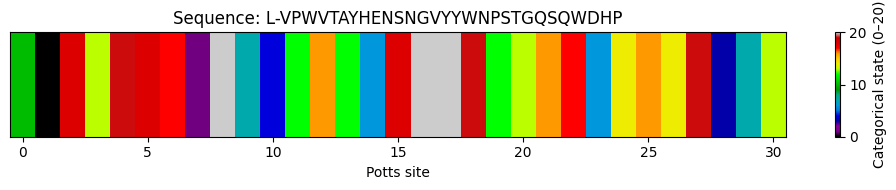

In [7]:
# Visualize a Sample
# Initialize once, outside both training loops.
id0 = torch.randint(q, (N,), device=device)
v0 = torch.nn.functional.one_hot(id0, num_classes=q).to(dtype=W.dtype)
v_sample1 = Block_Gibbs_sampling(v0, W, a, b, 1000)

decoded = v_sample1.argmax(dim=-1).cpu()  # [N]
sequence = "".join(alphabet[i] for i in decoded.tolist())

plt.figure(figsize=(10, 2))
plt.imshow(
    decoded.unsqueeze(0).numpy(),  # imshow needs 2D: [1, N]
    aspect="auto",
    interpolation="nearest",
    cmap="nipy_spectral",
    vmin=0,
    vmax=q - 1,
)
plt.yticks([])
plt.xlabel("Potts site")
plt.title(f"Sequence: {sequence}")
plt.colorbar(label=f"Categorical state (0–{q - 1})")
plt.tight_layout()
plt.show()

### Some Analysis to See if Generated Sequences Make Sense

Single-site MAE: 0.010554
Pairwise MAE, RBM: 0.000543
Pairwise MAE, independent: 0.000812
Exact training matches: 0.00%


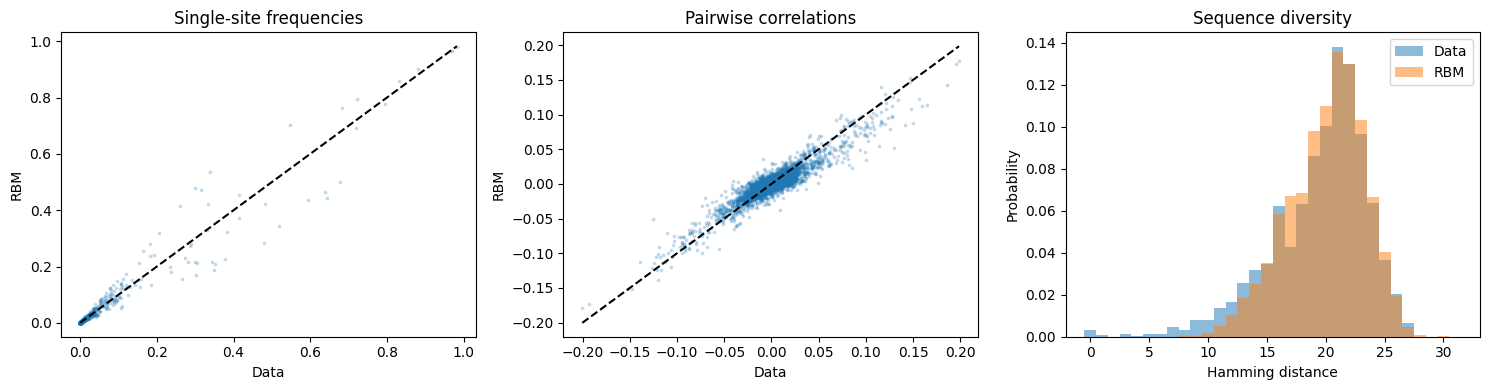

In [8]:
# W has shape [N, q, M]:
# N = sequence length, q = number of categories, M = hidden units
N, q, _ = W.shape

# For NumPy, separate from torch.manual_seed()
rng = np.random.default_rng(42)


# Generate 2000 sequences from the trained RBM.
with torch.no_grad():
    # Start each site in a uniformly random category
    ids = torch.randint(q, (2000, N), device=W.device)

    # Convert category indices [2000, N] to one-hot states [2000, N, q]
    v0 = torch.nn.functional.one_hot(ids, q).to(W.dtype)

    # Run 1000 Gibbs steps, then keep the final visible states
    generated = Block_Gibbs_sampling(v0, W, a, b, 1000)


# Convert one-hot states to integer category indices.
# After conversion, each row is a sequence of N integers from 0 to q-1
X_real = X_train.argmax(dim=-1).detach().cpu().numpy()
X_gen = generated.argmax(dim=-1).cpu().numpy()


def statistics(X):
    """X: [number of sequences, N], containing category indices."""
    n_sequences = len(X)
    # f[i, a] = fraction of sequences with category a at site i
    # bincount counts occurrences of each category
    # minlength=q includes categories that never appear
    f = np.array([
        np.bincount(X[:, i], minlength=q) / n_sequences
        for i in range(N)
    ])  # Shape: [N, q]

    C = []
    for i in range(N):
        for j in range(i + 1, N):
            # Encode each category pair (a, b) as the integer q*a + b
            # Counting these integers counts all q*q possible pairs
            pair_ids = q * X[:, i] + X[:, j]

            # joint[a, b] estimates P(X_i=a, X_j=b)
            joint = np.bincount(
                pair_ids, minlength=q*q
            ).reshape(q, q) / n_sequences

            # Under independence:
            # P(X_i=a, X_j=b) = P(X_i=a) * P(X_j=b)
            independent = np.outer(f[i], f[j])

            # Connected correlation:
            # C_ij(a,b) = joint probability - product of frequencies
            # Positive: pair occurs more often than independence predicts
            # Negative: pair occurs less often
            C.append(joint - independent)

    # One q-by-q matrix for each distinct pair of sites
    # Shape: [N*(N-1)//2, q, q]
    return f, np.array(C)


def hamming(X, n=2000):
    """Sample n sequence pairs and count differing sites in each pair."""
    # Draw two arrays of random row indices, with replacement
    i, j = rng.integers(len(X), size=(2, n))

    # Comparing sequences gives [n, N] booleans
    # Summing over sites gives n distances, each between 0 and N
    return (X[i] != X[j]).sum(axis=1)


# Measure single-site frequencies and connected pairwise correlations
f_real, C_real = statistics(X_real)
f_gen, C_gen = statistics(X_gen)


# Build an independent-site baseline
# It uses the data's category frequencies at every site, but samples
# different sites independently, removing dependencies between sites
X_ind = np.column_stack([
    rng.choice(q, size=len(X_gen), p=f) for f in f_real
])

# Its empirical correlations fluctuate around zero due to finite sampling
_, C_ind = statistics(X_ind)


# Average absolute frequency error across all N*q entries
print(f"Single-site MAE: {np.abs(f_real - f_gen).mean():.6f}")

# Average absolute connected-correlation error across all site/category pairs
# Compare the RBM with a model that contains no dependencies between sites
print(f"Pairwise MAE, RBM: {np.abs(C_real - C_gen).mean():.6f}")
print(f"Pairwise MAE, independent: {np.abs(C_real - C_ind).mean():.6f}")


# Fraction of generated sequences that exactly match any training sequence
# Tuples allow sequences to be stored in a set for fast membership checks
train_set = set(map(tuple, X_real))
match_rate = np.mean([tuple(row) in train_set for row in X_gen])
print(f"Exact training matches: {match_rate:.2%}")


fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Compare corresponding statistics: data on x-axis, RBM on y-axis
for axis, real, gen, title in [
    (ax[0], f_real, f_gen, "Single-site frequencies"),
    (ax[1], C_real, C_gen, "Pairwise correlations"),
]:
    # Flatten the arrays so each statistic becomes one plotted point
    axis.scatter(real.ravel(), gen.ravel(), s=3, alpha=0.2)

    # Points on this diagonal have identical data and RBM values
    limits = [min(real.min(), gen.min()), max(real.max(), gen.max())]
    axis.plot(limits, limits, "k--")
    axis.set(xlabel="Data", ylabel="RBM", title=title)


# Compare sequence diversity through random pairwise Hamming distances
for X, label in [(X_real, "Data"), (X_gen, "RBM")]:
    ax[2].hist(
        hamming(X),
        bins=np.arange(N + 2) - 0.5,  # One bin per integer distance 0,...,N
        density=True,               # Normalize; unit-width bins sum to 1
        alpha=0.5,
        label=label,
    )

ax[2].set(
    xlabel="Hamming distance",
    ylabel="Probability",
    title="Sequence diversity",
)
ax[2].legend()
plt.tight_layout()
plt.show()